# Experiment 8: Multi-Agent Task Allocation and Coordination
**Aim:** Implement task allocation using Partial Global Planning (PGP) and Contract Net Protocol (CNP).

In [1]:
import copy
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

## 1. Agent Setup
1 Manager + 3 Delivery Agents, 6 tasks, per-agent costs.

In [2]:
# Task -> (location, time slot)
TASKS = {
    "T1": ("Depot", 1),
    "T2": ("Depot", 1),
    "T3": ("Hub", 2),
    "T4": ("Market", 2),
    "T5": ("Market", 3),
    "T6": ("Station", 4),
}

# Cost/time each agent needs for each task
COSTS = {
    "A1": {"T1": 4, "T2": 9, "T3": 6, "T4": 8, "T5": 5, "T6": 7},
    "A2": {"T1": 6, "T2": 5, "T3": 7, "T4": 4, "T5": 9, "T6": 6},
    "A3": {"T1": 8, "T2": 6, "T3": 3, "T4": 7, "T5": 4, "T6": 5},
}
PRIORITY = {"A1": 1, "A2": 2, "A3": 3}  # lower number = higher priority


class DeliveryAgent:
    def __init__(self, name, costs):
        self.name, self.costs, self.tasks = name, costs, []

    def bid(self, task):
        return self.costs[task]

    def award(self, task):
        self.tasks.append(task)


class ManagerAgent:
    def __init__(self, agents):
        self.agents = agents

    def allocate(self, task, verbose=False):
        if verbose: print(f"1. Announcement : {task} at {TASKS[task][0]}, slot {TASKS[task][1]}")
        bids = {a.name: a.bid(task) for a in self.agents}
        if verbose: print(f"2. Bidding      : {bids}")
        winner = min(bids, key=lambda n: (bids[n], PRIORITY[n]))  # ties -> higher priority
        if verbose:
            print(f"3. Comparison   : lowest bid = {bids[winner]}")
            print(f"4. Selection    : {winner}")
        next(a for a in self.agents if a.name == winner).award(task)
        if verbose: print(f"5. Assignment   : {task} -> {winner}")
        return winner, bids[winner]


display(pd.DataFrame(TASKS, index=["Location", "Slot"]).T)
display(pd.DataFrame(COSTS).T)

,Location,Slot
T1,Depot,1
T2,Depot,1
T3,Hub,2
T4,Market,2
T5,Market,3
T6,Station,4


,T1,T2,T3,T4,T5,T6
A1,4,9,6,8,5,7
A2,6,5,7,4,9,6
A3,8,6,3,7,4,5


## 2. PGP Coordination
Local plans are merged into a partial global plan. Conflict = two agents at the same location at the same time. The lower-priority agent is delayed.

In [3]:
# Plan step: (time, location, action)
def show(plans):
    for ag, steps in plans.items():
        print(f"  {ag}: " + " -> ".join(f"t{t}@{loc}" for t, loc, _ in steps))

def detect_conflicts(plans):
    seen = {}
    for ag, steps in plans.items():
        for t, loc, _ in steps:
            seen.setdefault((loc, t), []).append(ag)
    return {k: v for k, v in seen.items() if len(v) > 1}

def resolve_conflicts(plans):
    plans = copy.deepcopy(plans)
    while True:
        conflicts = detect_conflicts(plans)
        if not conflicts:
            return plans
        (loc, t), ags = min(conflicts.items(), key=lambda kv: (kv[0][1], kv[0][0]))
        loser = max(ags, key=lambda a: PRIORITY[a])
        print(f"Conflict at {loc}, t={t}: {ags} -> delaying {loser} by 1")
        plans[loser] = [(s + 1 if s >= t else s, l, a) for s, l, a in plans[loser]]

local_plans = {
    "A1": [(1, "Depot", "pickup"),    (2, "Market", "deliver"),  (3, "Station", "deliver")],
    "A2": [(1, "Hub", "pickup"),      (2, "Market", "deliver"),  (3, "Depot", "deliver")],
    "A3": [(1, "Warehouse", "pickup"), (2, "Station", "deliver"), (3, "Hub", "deliver")],
}

print("Local plans:"); show(local_plans)
print("\nConflicts:", detect_conflicts(local_plans), "\n")
resolved = resolve_conflicts(local_plans)
print("\nResolved plans:"); show(resolved)
print("Remaining conflicts:", detect_conflicts(resolved))

Local plans:
  A1: t1@Depot -> t2@Market -> t3@Station
  A2: t1@Hub -> t2@Market -> t3@Depot
  A3: t1@Warehouse -> t2@Station -> t3@Hub

Conflicts: {('Market', 2): ['A1', 'A2']} 

Conflict at Market, t=2: ['A1', 'A2'] -> delaying A2 by 1

Resolved plans:
  A1: t1@Depot -> t2@Market -> t3@Station
  A2: t1@Hub -> t3@Market -> t4@Depot
  A3: t1@Warehouse -> t2@Station -> t3@Hub
Remaining conflicts: {}


## 3. CNP Task Allocation
One task, all five stages shown.

In [4]:
agents = [DeliveryAgent(n, c) for n, c in COSTS.items()]
manager = ManagerAgent(agents)
manager.allocate("T1", verbose=True);

1. Announcement : T1 at Depot, slot 1
2. Bidding      : {'A1': 4, 'A2': 6, 'A3': 8}
3. Comparison   : lowest bid = 4
4. Selection    : A1
5. Assignment   : T1 -> A1


## 4. Multiple Task Allocation
All tasks are allocated through CNP; PGP then checks the resulting plans.

In [5]:
def run_cnp(costs, verbose=False):
    agents = [DeliveryAgent(n, c) for n, c in costs.items()]
    manager = ManagerAgent(agents)
    rows = [(t, *manager.allocate(t, verbose)) for t in TASKS]
    df = pd.DataFrame(rows, columns=["Task", "Selected Agent", "Cost/Time"])
    return df, {a.name: a.tasks for a in agents}

def plans_from_allocation(alloc):
    plans = {}
    for ag, ts in alloc.items():
        steps, prev = [], 0
        for t in sorted(ts, key=lambda x: TASKS[x][1]):
            loc, slot = TASKS[t]
            time = max(slot, prev + 1)  # an agent does one task per time step
            steps.append((time, loc, f"deliver {t}"))
            prev = time
        plans[ag] = steps
    return plans

def agent_totals(df, costs):
    return df.groupby("Selected Agent")["Cost/Time"].sum().reindex(list(costs), fill_value=0)

df1, alloc1 = run_cnp(COSTS)
display(df1.style.hide(axis="index"))
print("Total cost/time:", df1["Cost/Time"].sum())

print("\nPGP check on CNP allocation:")
plans1 = plans_from_allocation(alloc1)
show(plans1)
final1 = resolve_conflicts(plans1)
print("Final plans:"); show(final1)

Task,Selected Agent,Cost/Time
T1,A1,4
T2,A2,5
T3,A3,3
T4,A2,4
T5,A3,4
T6,A3,5


Total cost/time: 25

PGP check on CNP allocation:
  A1: t1@Depot
  A2: t1@Depot -> t2@Market
  A3: t2@Hub -> t3@Market -> t4@Station
Conflict at Depot, t=1: ['A1', 'A2'] -> delaying A2 by 1
Conflict at Market, t=3: ['A2', 'A3'] -> delaying A3 by 1
Final plans:
  A1: t1@Depot
  A2: t2@Depot -> t3@Market
  A3: t2@Hub -> t4@Market -> t5@Station


## 5. Modification & Visualization
Changes: A3 costs +2 on all tasks, A1's T2 cost 9 → 2, A2's T6 cost 6 → 3.

In [6]:
COSTS2 = copy.deepcopy(COSTS)
COSTS2["A3"] = {t: c + 2 for t, c in COSTS2["A3"].items()}
COSTS2["A1"]["T2"] = 2
COSTS2["A2"]["T6"] = 3

df2, alloc2 = run_cnp(COSTS2)
display(df2.style.hide(axis="index"))
print("Total cost/time:", df2["Cost/Time"].sum())

print("\nPGP check on new allocation:")
plans2 = plans_from_allocation(alloc2)
show(plans2)
resolve_conflicts(plans2);
print("No conflicts." if not detect_conflicts(plans2) else "")

# Comparison
cmp = df1.merge(df2, on="Task", suffixes=(" (Before)", " (After)"))
display(cmp.style.hide(axis="index"))

Task,Selected Agent,Cost/Time
T1,A1,4
T2,A1,2
T3,A3,5
T4,A2,4
T5,A1,5
T6,A2,3


Total cost/time: 23

PGP check on new allocation:
  A1: t1@Depot -> t2@Depot -> t3@Market
  A2: t2@Market -> t4@Station
  A3: t2@Hub
No conflicts.


Task,Selected Agent (Before),Cost/Time (Before),Selected Agent (After),Cost/Time (After)
T1,A1,4,A1,4
T2,A2,5,A1,2
T3,A3,3,A3,5
T4,A2,4,A2,4
T5,A3,4,A1,5
T6,A3,5,A2,3


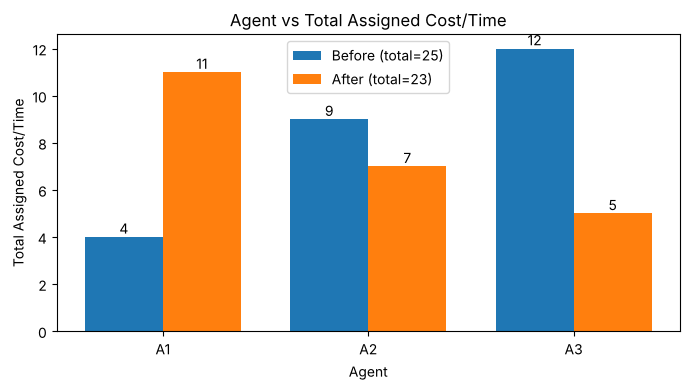

In [7]:
t1, t2 = agent_totals(df1, COSTS), agent_totals(df2, COSTS2)
x = range(len(t1)); w = 0.38

fig, ax = plt.subplots(figsize=(7, 4))
b1 = ax.bar([i - w/2 for i in x], t1.values, w, label=f"Before (total={t1.sum()})")
b2 = ax.bar([i + w/2 for i in x], t2.values, w, label=f"After (total={t2.sum()})")
ax.bar_label(b1); ax.bar_label(b2)
ax.set_xticks(list(x)); ax.set_xticklabels(t1.index)
ax.set_xlabel("Agent"); ax.set_ylabel("Total Assigned Cost/Time")
ax.set_title("Agent vs Total Assigned Cost/Time")
ax.legend(); plt.tight_layout(); plt.show()

## Observation
- **PGP:** merging local plans exposed a resource clash; delaying the lower-priority agent resolved it (and any knock-on clash).
- **CNP:** each task goes to the lowest bidder, so the allocation follows the cost matrix.
- **Input change:** higher A3 costs and cheaper A1/A2 bids shifted tasks between agents and lowered the total cost/time.